# R7 · Limites et dérivation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r7_limites_derivation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R7.1 à R7.11, R7.15 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R7.17 | Le taux d'accroissement · `difference_quotient` | 🔨 | ★ | 15 |
|  | R7.18 | La tangente à partir de f et de sa dérivée · `tangent_line` | 🔨 | ★★ | 20 |
|  | R7.19 | Trouver un zéro par dichotomie · `bisection` | 🔨 | ★★ | 25 |
| B | R7.20 | Vérifier ses dérivées avec `sympy.diff` | 📦 | ★ | 15 |
|  | R7.21 | Prédire : le taux d'accroissement s'approche-t-il toujours de la dérivée quand h devient minuscule ? | 🔮 | ★★ | 15 |
|  | R7.22 | Zoomer sur une courbe jusqu'à voir une droite | 🔬 | ★★ | 20 |
|  | R7.23 | Tracer f, f′ et des tangentes | 🎨 | ★★ | 20 |
| C | R7.24 | Chasse à l'erreur : quatre dérivées fausses | 🐛 | ★★ | 20 |
|  | R7.25 | Tester une dérivée avec pytest et SymPy | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : limites et asymptotes, taux d'accroissement, tangentes, dérivées (usuelles, produits, quotients, composées, une lettre à la fois), variations et optimisation.
- Écrire les trois fonctions de `mymath/deriv.py` et les tester.
- Dériver avec SymPy, voir ce que deviennent les taux d'accroissement en flottants, zoomer sur une courbe, tracer f et f′, chasser des dérivées fausses et écrire un test.

**Rappel express.** $f'(a) = \lim_{h \to 0} \frac{f(a + h) - f(a)}{h}$ ; tangente : $y = f(a) + f'(a)(x - a)$. $(x^n)' = n x^{n-1}$, $(e^x)' = e^x$, $(\ln x)' = \frac{1}{x}$, $(\sqrt{x})' = \frac{1}{2\sqrt{x}}$. $(uv)' = u'v + uv'$, $\left(\frac{u}{v}\right)' = \frac{u'v - uv'}{v^2}$, $\big(g(u)\big)' = g'(u) \times u'$. $f' > 0$ : $f$ croît ; un extremum intérieur annule $f'$.

## Partie 0 · Vérifier tes exercices papier (✏️ R7.1 à R7.11, 🔗 R7.15)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5`, arrondi comme le demande la question ; une limite infinie par `"+oo"` ou `"-oo"` ;
- une fraction exacte entre guillemets, `"5/7"` ;
- une expression entre guillemets, `"3*x**2 - 1"` (`*` pour multiplier, `**` pour la puissance ; `exp(x)`, `log(x)` pour ln x, `sqrt(x)`, `pi`) ;
- un intervalle entre guillemets, `"[-2 ; 4["` (`-oo` et `+oo` pour l'infini) ;
- une liste de nombres entre crochets (une tangente $y = mx + p$ par `[m, p]`) ; vrai ou faux par `True` ou `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex R7.1 — Limites en l'infini des fonctions de référence**

In [3]:
wbm.record("R7.1a", 5.0, decimals=2, mistakes={"3/x tend vers 0 : il reste le premier terme": 2})
wbm.record("R7.1b", math.inf, decimals=2, mistakes={"∞ − ∞ est une forme indéterminée, pas 0 : mets le terme de plus haut degré en facteur": 0})
wbm.record("R7.1c", 2.0, decimals=2, mistakes={"en l'infini, ce sont les termes de plus haut degré qui comptent, pas les constantes": {-0.33, 0.33}})
wbm.record("R7.1d", 0.0, decimals=2, mistakes={"le degré du dénominateur est plus grand que celui du numérateur": math.inf, "en l'infini, les termes de plus haut degré décident, pas les constantes": 0.5})
wbm.record("R7.1e", 1.0, decimals=2, mistakes={"e^(−2x) tend vers 0, mais un terme constant s'y ajoute": 0})
wbm.record("R7.1f", 0.0, decimals=2, mistakes={"croissances comparées : l'exponentielle l'emporte sur toute puissance": math.inf})
wbm.record("R7.1g", math.inf, decimals=2, mistakes={"croissances comparées : toute puissance de x, même √x, l'emporte sur ln x": 0})
wbm.record("R7.1h", -math.inf, decimals=2, mistakes={"quand x est négatif, x³ l'est aussi : regarde le signe du terme dominant": math.inf})

WBM_ANSWER {"decimals": 2, "hash": "04a73b77219c7a2914e4edf7d40b5f912acd8a3ca63d922be0150f2d6a7a3fa3", "hash_coarse": "79e81dd676fc362f0a281fbfa2ac4a644b6ca2dc2f5098dfd3b80f14883b1d76", "id": "R7.1a", "kind": "float", "magnitude": 0, "mistakes": {"99bf77b58bdfbb633937a25cc874fbe200f5456a4db43bfdb735ecb0c2f82bf9": "3/x tend vers 0 : il reste le premier terme"}, "sign": 1}
📝 Ex R7.1a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "585146b78422606d07d81e1669a0d45467c035e3803caf9facfba41c0ae3baea", "hash_coarse": "585146b78422606d07d81e1669a0d45467c035e3803caf9facfba41c0ae3baea", "id": "R7.1b", "kind": "float", "magnitude": null, "mistakes": {"56ccfcb157d6ae882c73db24ece3dd13ba6dbcd4556af01c185d91406e3b650d": "∞ − ∞ est une forme indéterminée, pas 0 : mets le terme de plus haut degré en facteur"}, "sign": 1}
📝 Ex R7.1b : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "fe688ddcac993fa2c5a301bc5cf5f685f477e8c818bcf3d11a74800a5

**Ex R7.2 — Limites et asymptotes de fonctions rationnelles**

In [4]:
wbm.record("R7.2a", 3.0, decimals=2, mistakes={"en l'infini, les termes de plus haut degré décident, pas les constantes": -2})
wbm.record("R7.2b", -math.inf, decimals=2, mistakes={"en −1, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie": {-5, 0}})
wbm.record("R7.2c", math.inf, decimals=2, mistakes={"en −1, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie (et regarde son signe à gauche)": {-5, 0}})
wbm.record("R7.2d", [-1, 3], mistakes={"l'asymptote verticale est là où le dénominateur s'annule, pas le numérateur": [2 / 3, 3], "la liste est [a, L] : d'abord l'abscisse de l'asymptote verticale": [3, -1]})
wbm.record("R7.2e", 5.0, decimals=2, mistakes={"0/0 est une forme indéterminée, pas une limite : factorise le numérateur": 0, "après la factorisation, la limite se calcule en remplaçant x par 2": 3})
wbm.record("R7.2f", False, mistakes={"le numérateur s'annule aussi en 2 : factorise avant de conclure": True})
wbm.record("R7.2g", [-3, 3], mistakes={"x² − 9 = 0 a deux solutions": [3], "le dénominateur s'annule en ces points, pas le numérateur": [-1.22, 1.22]})
wbm.record("R7.2h", math.inf, decimals=2, mistakes={"en 3, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie": {21, 2, 0}})

WBM_ANSWER {"decimals": 2, "hash": "9b828c4278204601847476897c7b53f8aa6425b20a6d5a9a9d1a22bcd097f2de", "hash_coarse": "7f3625a5daeb33e9234815c3a9bb6ab23914148087b3cef0fb44f35a466aaef2", "id": "R7.2a", "kind": "float", "magnitude": 0, "mistakes": {"eeee0a070d98c1435579790b270cdbec073f3c40eede5643459f1a985b116250": "en l'infini, les termes de plus haut degré décident, pas les constantes"}, "sign": 1}
📝 Ex R7.2a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "6d17052e1383a570aecf5bf466c81b3e202809c5d346da93933f3d09a4355c45", "hash_coarse": "6d17052e1383a570aecf5bf466c81b3e202809c5d346da93933f3d09a4355c45", "id": "R7.2b", "kind": "float", "magnitude": null, "mistakes": {"1b46c9c8a39384d2cad45b4b1f7ab9bec63b0a10cce4b9b545218bfa0c78e0fa": "en −1, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie", "59fd84c11cd175acb92eb8e3bc0e66b5d720c77c3f84c18562862bf1dda62055": "en −1, le dénominateur s'annule mais pas le numérateur : la limite n

**Ex R7.3 — Taux d'accroissement et nombre dérivé**

In [5]:
wbm.record("R7.3a", 4.0, decimals=2, mistakes={"le taux est une différence de deux valeurs de f, divisée par h": {-4, 0}})
wbm.record("R7.3b", 3.1, decimals=2, mistakes={"divise la différence des valeurs de f par h = 0,1": 0.31})
wbm.record("R7.3c", 2.5, decimals=2, mistakes={"h est négatif : on divise par −0,5, pas par 0,5": -2.5})
wbm.record("R7.3d", "3 + h", kind="expr", variables=("h",), mistakes={"le taux dépend encore de h ; sa limite viendra en e)": "3", "développe (4 + h)² avant de simplifier par h": "8 + h"})
wbm.record("R7.3e", 3.0, decimals=2, mistakes={"f′(4) est la limite du taux quand h tend vers 0, pas sa valeur pour h = 1": 4, "f′(4) est une pente, pas la valeur f(4)": -4})
wbm.record("R7.3f", 22.5, decimals=2, mistakes={"une vitesse moyenne : la distance parcourue divisée par la durée, 0,5 s": 11.25, "la distance parcourue entre t = 2 et t = 2,5, pas depuis le départ": 62.5})
wbm.record("R7.3g", 20.0, decimals=2, mistakes={"c'est la vitesse moyenne de f) ; la vitesse instantanée est la limite quand la durée tend vers 0": 22.5})
wbm.record("R7.3h", 3.0, decimals=2, mistakes={"le taux d'une fonction affine est sa pente, pas son ordonnée à l'origine": 7})

WBM_ANSWER {"decimals": 2, "hash": "a2881cd8a6e5bb496c05150d0a60f65b84dd3258bffc9846a6e38101b7e20339", "hash_coarse": "1105676746c149cac362374f337a930ad127c6f5a3f3a952fa1b7644bb3c0904", "id": "R7.3a", "kind": "float", "magnitude": 0, "mistakes": {"7a0a06ca7b5b73ec0a72f4c182a668c3afd1bcc46146d0664b5c03155e13120a": "le taux est une différence de deux valeurs de f, divisée par h", "820b8de874cb28501724cde95900f00063bf04d4868af050ebcbda3b440000d8": "le taux est une différence de deux valeurs de f, divisée par h"}, "sign": 1}
📝 Ex R7.3a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "5cf28839cde791765d8b08e50a4a8089593e17a573b012159f291645515a3637", "hash_coarse": "3c3c6a95f3f42bf8f2ab65ebd33d961c3c205289f7acbfed3781a29d869f9ec8", "id": "R7.3b", "kind": "float", "magnitude": 0, "mistakes": {"d2ae1c575e6706ed35fbdaa16c36b7fa0fd4fa662a495b41d705c564b815a91f": "divise la différence des valeurs de f par h = 0,1"}, "sign": 1}
📝 Ex R7.3b : réponse enregistrée (fl

WBM_ANSWER {"hash": "73f7d75fcb61c898ca88d71684eda40b593d4f57357e2468fe59070105e0cec3", "id": "R7.3d", "kind": "expr", "mistakes": {"1c7f4dbff1172fb5c26840e186cd8cc3fb2b9589f2d033de59388e5233659c51": "développe (4 + h)² avant de simplifier par h", "e52b3a81f59ef71a84f0bb2458cff64f7b328083e1da2dd6a2b9af5aaf21e7b3": "le taux dépend encore de h ; sa limite viendra en e)"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["h"]}
📝 Ex R7.3d : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "086669dcf7c65d71a4e62263bb2415055a081ca1a49b3fd47f0c211dce8040b8", "hash_coarse": "8fce259146bb7d3124b05208f28a4031f4bb39941dd9067eb8ac9454bf520b7d", "id": "R7.3e", "kind": "float", "magnitude": 0, "mistakes": {"8fa4a217d39136892f086baacff546482dd0586b952537893e05e68b8ba86a15": "f′(4) est la limite du taux quand h tend vers 0, pas sa valeur pour h = 1", "e035778b85e43f8f2416af7e9bbfa8e19475c1caec90ca17f5ac98f90152b2da": "f′(4) est une pente, pas la valeur f(4)"}, "sig

**Ex R7.4 — Équation de la tangente**

In [6]:
wbm.record("R7.4a", [3, -16], mistakes={"p n'est pas f(4) : développe f(4) + f′(4)(x − 4)": [3, -4], "p = f(a) − f′(a) × a : vérifie le signe": [3, 8]})
wbm.record("R7.4b", [math.e, 0.0], decimals=3, mistakes={"la pente en 1 est e¹, pas 1": [1, math.e - 1]})
wbm.record("R7.4c", [0.5, math.log(2) - 1], decimals=3, mistakes={"p = f(2) − f′(2) × 2 : f(2) = ln 2": [0.5, -1], "la pente de ln en 2 est 1/2, pas ln 2": [math.log(2), math.log(2) - 2 * math.log(2)]})
wbm.record("R7.4d", [0.25, 1.0], decimals=2, mistakes={"(√x)′ = 1/(2√x) : en 4, 1/(2 × 2)": [0.5, 0]})
wbm.record("R7.4e", 2.05, decimals=2, mistakes={"remplace x par 4,2 dans l'équation de la tangente de d)": 1.05})
wbm.record("R7.4f", round(2.05 - math.sqrt(4.2), 5), decimals=5, mistakes={"approximation moins vraie valeur, dans cet ordre": -round(2.05 - math.sqrt(4.2), 5)})
wbm.record("R7.4g", 2.5, decimals=2, mistakes={"une tangente horizontale a une pente nulle : résous f′(x) = 0, pas f(x) = 0": 5})
wbm.record("R7.4h", Fraction(2, 3), kind="fraction", mistakes={"la tangente coupe l'axe des abscisses là où y = 0 : résous 3x − 2 = 0": "-2"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["bcc346e06adcf9a56b3c4d47be18be4f71df2b591fa15cb61cc8851448b7a968", "b4a2109b063673aea6cf909fb9ff57dbd6325ec43cdb5d207af133e122454c14"], "hash": "99195ee9156aff8822cc6b0879f41e5685b4824e6264d4fb26e8804db4817f32", "id": "R7.4a", "integer": true, "kind": "array", "mistakes": {"9663c2b87b9d88f0447df87daee04db9c90d2b532f8d45d4a81e5a5222ffa259": "p = f(a) − f′(a) × a : vérifie le signe", "a82cf3860b791632151fd367cf6780e68eafbd24b7489e0d5bb8ac8e612931f0": "p n'est pas f(4) : développe f(4) + f′(4)(x − 4)"}, "shape": [2]}
📝 Ex R7.4a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 3, "element_coarse": [["dad2c4f8e84067879e8bf3ded959a9184d4262829d404d8e82727f7b9c0a2a7b"], ["1db4127835e5fe70731c0fada9b4e0c327e32d4c20e10f5bd42a3d6240282f19"]], "element_hashes": ["9d4c4a027283773763d43e171aace021f6bb5b335ca2a4e2f25ed3b2908f38af", "1317ba6cd6bc9c4f0c68752508e093a0fcbdea86968ead773043ba643d531110"], "hash": "3b5a0d5b88cf2d40d96f1521

**Ex R7.5 — Dériver les fonctions usuelles**

In [7]:
wbm.record("R7.5a", "7*x**6", kind="expr", variables=("x",), mistakes={"l'exposant descend devant, et diminue de 1": "7*x**7"})
wbm.record("R7.5b", "12*x**5 - 21*x**2 + 1", kind="expr", variables=("x",), mistakes={"la dérivée de x est 1, pas 0": "12*x**5 - 21*x**2", "chaque exposant diminue de 1 après être descendu devant": "12*x**6 - 21*x**3 + x"})
wbm.record("R7.5c", "-3/x**4", kind="expr", variables=("x",), mistakes={"écris 1/x³ = x^(−3) : l'exposant −3 descend devant, et diminue de 1": "-3/x**2", "1/x³ n'est pas une puissance positive : écris-la x^(−3)": "1/(3*x**2)"})
wbm.record("R7.5d", "3*sqrt(x)/2", kind="expr", variables=("x",), mistakes={"x√x n'est pas √x : écris-le x^(3/2)": "1/(2*sqrt(x))", "(x√x)′ n'est pas 1 × (√x)′ : écris x√x = x^(3/2)": "1/(2*sqrt(x)) + 1"})
wbm.record("R7.5e", "2/(3*x**(1/3))", kind="expr", variables=("x",), mistakes={"l'exposant diminue de 1 : 2/3 − 1": "2/3*x**(5/3)"})
wbm.record("R7.5f", "3*exp(x) - 4/x", kind="expr", variables=("x",), mistakes={"(ln x)′ = 1/x : c'est 1/x qui a pour dérivée −1/x²": "3*exp(x) + 4/x**2", "une constante multiplicative reste devant": "exp(x) - 1/x"})
wbm.record("R7.5g", "1/x", kind="expr", variables=("x",), mistakes={"ln(5x) = ln 5 + ln x, et ln 5 est une constante": "1/(5*x)", "ln(5x) = ln 5 + ln x : la constante ln 5 disparaît en dérivant, le 5 ne sort pas": "5/x"})
wbm.record("R7.5h", "exp(x + 2)", kind="expr", variables=("x",), mistakes={"e^(x + 2) = e² × eˣ : la constante e² reste devant": "exp(x)"})

WBM_ANSWER {"hash": "9b2c21180a0c4a682429fdba96eaefe9f1730b6228fd0bad088a6009f1cfa176", "id": "R7.5a", "kind": "expr", "mistakes": {"5e514d4ddd33fdfd6d740e7b242ed64b2a0de530553a400b98c825dc2364eb9f": "l'exposant descend devant, et diminue de 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.5a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7643fd8563cebe47d8b71d11b968450ef330e636076b566b226707e54d810baa", "id": "R7.5b", "kind": "expr", "mistakes": {"40e7bbfb36ec6d344c9cc51123d3e64e9e2274f6e72ff1b15eafa9b52301c029": "la dérivée de x est 1, pas 0", "9d8b4166214f06a8c8796902d51f66fc453929fc8d528c9367724ccf50220d7c": "chaque exposant diminue de 1 après être descendu devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.5b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "869c52f3ee4cbe1db70a73dd74cb3e076d20e65550002e24d400424d67e6d59a", "id": "R7.5c", "kind": "expr", "mistakes": {"cd5f368a8a6bdf1b5ed4cc

**Ex R7.6 — Dériver des produits et des quotients**

In [8]:
wbm.record("R7.6a", "3*x**2*log(x) + x**2", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "3*x", "(uv)′ = u′v + uv′ : il manque un des deux termes": "3*x**2*log(x)"})
wbm.record("R7.6b", "9*x**2 - 4*x + 3", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "6*x"})
wbm.record("R7.6c", "log(x)/(2*sqrt(x)) + 1/sqrt(x)", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "1/(2*x**(3/2))"})
wbm.record("R7.6d", "9/(2*x + 1)**2", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "-9/(2*x + 1)**2", "la dérivée d'un quotient n'est pas le quotient des dérivées": "1/2", "le dénominateur est v², pas v": "9/(2*x + 1)"})
wbm.record("R7.6e", "(1 - x**2)/(x**2 + 1)**2", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "(x**2 - 1)/(x**2 + 1)**2", "la dérivée d'un quotient n'est pas le quotient des dérivées": "1/(2*x)"})
wbm.record("R7.6f", "(1 - 2*log(x))/x**3", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "(2*log(x) - 1)/x**3", "le dénominateur est v² = x⁴ ; simplifie ensuite par x": "(1 - 2*log(x))/x**4"})
wbm.record("R7.6g", 1.0, decimals=2, mistakes={"ln 1 = 0 : un des deux termes s'annule, pas les deux": 0, "la dérivée d'un produit n'est pas le produit des dérivées": 3})
wbm.record("R7.6h", "-2*x/(x**2 + 4)**2", kind="expr", variables=("x",), mistakes={"(1/v)′ = −v′/v² : n'oublie pas v′ au numérateur": "-1/(x**2 + 4)**2", "la dérivée de 1/v n'est pas 1/v′": "1/(2*x)", "(1/v)′ = −v′/v² : un signe moins": "2*x/(x**2 + 4)**2"})

WBM_ANSWER {"hash": "3ec6cbf3ce9cbcf07c1ab7ab31cbd9f0aa639e4eb150817f36dfc8e55f7af2a1", "id": "R7.6a", "kind": "expr", "mistakes": {"6f6a3423bd6cf70be8f17379e45b97efa04067a5c87d39e2e7111b4a46f808ee": "la dérivée d'un produit n'est pas le produit des dérivées", "d4104dc5c14c8edacfda58ed58cedd3177bb282883a4b582b261ae8d1695d8f8": "(uv)′ = u′v + uv′ : il manque un des deux termes"}, "points": [["1/3"], ["5/7"], ["6/5"], ["9/4"], ["3/11"]], "variables": ["x"]}
📝 Ex R7.6a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "b31079249698d23f77cbd3d717c2b6429fd4a7d3b63579270b0cbe84db59c64a", "id": "R7.6b", "kind": "expr", "mistakes": {"8e25e619dc8e62403347fa168c9675f697d5381c3dc633ed05fbf80ed41cfed9": "la dérivée d'un produit n'est pas le produit des dérivées"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "ea7ed171f31a06fcd1c80eb2debe2bfc1da49deb1490a9b1da6d1eab8b24027b", "id": "R7.6c", "kind": "expr",

WBM_ANSWER {"hash": "9b42a68603f5b981c98309a60fb2bf81dcf112dd7c038f252c065e52f30bc328", "id": "R7.6e", "kind": "expr", "mistakes": {"7c48e71ad0ca093067fe0fb4fb6f532c5cc49401e3ff9e60d45ec9ef5a93fc68": "la dérivée d'un quotient n'est pas le quotient des dérivées", "a353f8b4285bb83dee961201af997c354147eddaa66adb5f9314863509a6827b": "u′v − uv′, dans cet ordre, au numérateur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6e : réponse enregistrée (expr).


WBM_ANSWER {"hash": "29b51e299bf944b75cf773308def28062f06b28c82851721b91d9cf48c981aba", "id": "R7.6f", "kind": "expr", "mistakes": {"4af874caa131ed9592f226bbf951981448989ce245a2f6a19d017f8496fe7e3e": "u′v − uv′, dans cet ordre, au numérateur", "908244af362a0ac838ec93c8c5790d5db209da77b5f28a1a5a28f8c509f7e94b": "le dénominateur est v² = x⁴ ; simplifie ensuite par x"}, "points": [["1/3"], ["5/7"], ["6/5"], ["9/4"], ["3/11"]], "variables": ["x"]}
📝 Ex R7.6f : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "4edcb65f16533c15e23afe0da1f35e715c3836a4edf022f247f116c8c13d6045", "hash_coarse": "aa1656aaf918a581051b899af6e18282dcc824f90ecab7226cc14be0a081e740", "id": "R7.6g", "kind": "float", "magnitude": 0, "mistakes": {"412b4c863e8ad89f23f0137ffa4c303603412afd9f27d8309c69a62eedc19f95": "ln 1 = 0 : un des deux termes s'annule, pas les deux", "44eb8d09b53e12e3f92e33a6ea5e3eca1b76c049b4f2e87da2bced80e19a39be": "la dérivée d'un produit n'est pas le produit des dérivées"}, "sign": 1}

WBM_ANSWER {"hash": "92fc68e2a5d765fe4be6cbae0d0e4df170d3bd65c41892530574689ba2ee4acd", "id": "R7.6h", "kind": "expr", "mistakes": {"036d4e455695c05f50d38152f8dba433d4c67c7f7edf8d93d408ff5c6e2e85db": "la dérivée de 1/v n'est pas 1/v′", "2baf6580666859ff2f51aa2a959dfb59f697ba95216a14b9061a5b53b40bc48f": "(1/v)′ = −v′/v² : un signe moins", "ef81932680059e78bc1f7bc688f2af927924978c672cf89ad2d6dc87735b389c": "(1/v)′ = −v′/v² : n'oublie pas v′ au numérateur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6h : réponse enregistrée (expr).


**Ex R7.7 — Dériver des composées**

In [9]:
wbm.record("R7.7a", "12*x*(2*x**2 - 1)**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur": "3*(2*x**2 - 1)**2"})
wbm.record("R7.7b", "5*exp(5*x - 3)", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur": "exp(5*x - 3)"})
wbm.record("R7.7c", "3/(3*x + 2)", kind="expr", variables=("x",), mistakes={"(ln u)′ = u′/u : multiplie par la dérivée de l'étage intérieur": "1/(3*x + 2)"})
wbm.record("R7.7d", "-1/(2*sqrt(4 - x))", kind="expr", variables=("x",), mistakes={"l'étage intérieur 4 − x a pour dérivée −1": "1/(2*sqrt(4 - x))"})
wbm.record("R7.7e", "exp(sqrt(x))/(2*sqrt(x))", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur √x": "exp(sqrt(x))"})
wbm.record("R7.7f", "1/(x*log(x))", kind="expr", variables=("x",), mistakes={"(ln u)′ = u′/u : ici u = ln x, et u′ n'est pas 1": "1/log(x)"})
wbm.record("R7.7g", "-(2*x + 1)/(x**2 + x)**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur": "-1/(x**2 + x)**2", "(u^(−1))′ = −u^(−2) × u′ : un signe moins": "(2*x + 1)/(x**2 + x)**2"})
wbm.record("R7.7h", Fraction(4, 3), kind="fraction", mistakes={"(ln u)′ = u′/u : multiplie par u′ avant de remplacer x par 1": "1/3"})

WBM_ANSWER {"hash": "0238f4f8c58a1c220830d5c3578d04e47fcae05f75716b79c0943f838d48b9b1", "id": "R7.7a", "kind": "expr", "mistakes": {"af343c7885ced9912d624b32dfc40aea72b570abe1c0b1401688f590345ad013": "multiplie par la dérivée de l'étage intérieur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.7a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "0b5dda8d87659f47a376f3991632c199426173544e1586913daf6315f6cb4c89", "id": "R7.7b", "kind": "expr", "mistakes": {"c1606ec7ef2b13be58eaaccb3439a164ff7b8005724529f1bd91f394d2beb525": "multiplie par la dérivée de l'étage intérieur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.7b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "3774788513a63e06e01cd6ac44cd67caab4056ceb5db8c345ff7c18adc04c9b8", "id": "R7.7c", "kind": "expr", "mistakes": {"3af7c673dd9f3bc7bcf56592fb0f66393c3451e5894c3c399273a1480c6a8920": "(ln u)′ = u′/u : multiplie par la dérivée de l'étage intérieu

**Ex R7.8 — Variations et tableau de variations**

In [10]:
wbm.record("R7.8a", "6*x**2 + 6*x - 12", kind="expr", variables=("x",), mistakes={"la dérivée de la constante 1 est 0, et chaque exposant diminue de 1": "6*x**2 + 6*x - 11"})
wbm.record("R7.8b", [-2, 1], mistakes={"6x² + 6x − 12 = 6(x² + x − 2) : vérifie les racines du second degré": [-1, 2]})
wbm.record("R7.8c", "[-2 ; 1]", kind="interval", mistakes={"les bornes, où f′ s'annule, sont comprises : f y est décroissante jusqu'au bout": "]-2 ; 1[", "f décroît là où f′ < 0, entre les racines (le coefficient de x² est positif)": "[1 ; +oo["})
wbm.record("R7.8d", 21.0, decimals=2, mistakes={"c'est l'abscisse du maximum local ; on demande la valeur de f en ce point": -2})
wbm.record("R7.8e", -6.0, decimals=2, mistakes={"c'est l'abscisse du minimum local ; on demande la valeur de f en ce point": 1})
wbm.record("R7.8f", 46.0, decimals=2, mistakes={"sur un intervalle fermé, compare aussi les valeurs de f aux bords": 21})
wbm.record("R7.8g", 2.0, decimals=2, mistakes={"g′(x) = 1 − 2/x : résous g′(x) = 0, pas g(x) = 0": {0.5, 0}})
wbm.record("R7.8h", round(2 - 2 * math.log(2), 3), decimals=3, mistakes={"c'est l'abscisse du minimum ; on demande la valeur de g en ce point": 2, "g(2) = 2 − 2 ln 2, avec ln et pas log₁₀": round(2 - 2 * math.log10(2), 3)})

WBM_ANSWER {"hash": "c03c101b7146d20c6beead08daabb1ae7db010e35946cf7999f979fa75d22347", "id": "R7.8a", "kind": "expr", "mistakes": {"241234693376635fbfba38906105a6bffc0d83a9051f42f2e1b23a0f9fa1a00c": "la dérivée de la constante 1 est 0, et chaque exposant diminue de 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.8a : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 0, "element_hashes": ["c5e686429eb7e435498deabd84db1eecac5214b2fd3b97779b80b66361db9181", "eb1852ff081628ed6cccd8e07598d52047dfbdda1862f097fd50fb131c4b9293"], "hash": "e0932edd9550b05cb748de8b8dc2568785320e1824ed0834a48006c80e4d03aa", "id": "R7.8b", "integer": true, "kind": "array", "mistakes": {"0cb91df869962a8b2b35e229b840420c396841243d83420c12fdd19383ea8fdf": "6x² + 6x − 12 = 6(x² + x − 2) : vérifie les racines du second degré"}, "shape": [2]}
📝 Ex R7.8b : réponse enregistrée (array, 0 décimale(s)).


WBM_ANSWER {"hash": "3c0fbf28518b0f2140ba0ce3c627eff455d75717b6f9d294f22513858c61a1c2", "id": "R7.8c", "kind": "interval", "mistakes": {"979ad4b893e399d9995f15b5e5cfa76f1c7d20a1326c3216e94663d0809a978d": "les bornes, où f′ s'annule, sont comprises : f y est décroissante jusqu'au bout", "9d91cec9ae7d37d054f62943241af8cf864f5b945188a7a9f1f55e3d167a169b": "f décroît là où f′ < 0, entre les racines (le coefficient de x² est positif)"}}
📝 Ex R7.8c : réponse enregistrée (interval).
WBM_ANSWER {"decimals": 2, "hash": "0ed5ccddbb14911d030aa7900e2c259ea86279f7aaa93a27ec2426a7a5cab7c5", "hash_coarse": "f8fa0db6ea0aa58918f2207f9f8f52a5afc270e33637ebc8a7374ba3b53406de", "id": "R7.8d", "kind": "float", "magnitude": 1, "mistakes": {"b392218d84d42ff489a8348985e7d56d9861a243bceead427f04f91a324ac4d6": "c'est l'abscisse du maximum local ; on demande la valeur de f en ce point"}, "sign": 1}
📝 Ex R7.8d : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "228ba17d4e5fc5082dd38e

**Ex R7.9 — Optimiser : la boîte de volume maximal**

In [11]:
wbm.record("R7.9a", "]0 ; 5[", kind="interval", mistakes={"en x = 0 ou x = 5, la boîte est plate : les bornes sont exclues": "[0 ; 5]", "deux découpes de x sont prises sur le côté de 10 cm : 10 − 2x doit rester positif": "]0 ; 8["})
wbm.record("R7.9b", "4*x**3 - 52*x**2 + 160*x", kind="expr", variables=("x",), mistakes={"développe (16 − 2x)(10 − 2x) avant de multiplier par x": "4*x**3 - 52*x**2 + 160"})
wbm.record("R7.9c", "12*x**2 - 104*x + 160", kind="expr", variables=("x",), mistakes={"chaque exposant diminue de 1 après être descendu devant": "12*x**3 - 104*x**2 + 160*x"})
wbm.record("R7.9d", 2.0, decimals=2, mistakes={"cette racine n'est pas dans le domaine : la largeur 10 − 2x serait négative": round(20 / 3, 2)})
wbm.record("R7.9e", 144.0, decimals=2, mistakes={"le volume est V(x) au point trouvé, pas V′": 0})
wbm.record("R7.9f", [12, 6, 2], mistakes={"la longueur et la largeur perdent 2x, pas x": [14, 8, 2], "longueur, largeur, hauteur, dans cet ordre": [6, 12, 2]})

WBM_ANSWER {"hash": "872a3cd29e90a36f0db331178a20d81f1c7d62086bc3d72a0f6401779270d3de", "id": "R7.9a", "kind": "interval", "mistakes": {"187023c79992dfd941651a205412323454c1867f0053601d6cf22bc8eb592a57": "en x = 0 ou x = 5, la boîte est plate : les bornes sont exclues", "a24334af7618c2bcee22e7f21f26a43024789714510492524dc12e8b46173c99": "deux découpes de x sont prises sur le côté de 10 cm : 10 − 2x doit rester positif"}}
📝 Ex R7.9a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "ded1588c92cdb530264f9137b242749919a9d89172c2cb4c60a5ddc98db32052", "id": "R7.9b", "kind": "expr", "mistakes": {"5079433bab28b67743c2749d7173465a03e3864d22689a4c25dadab1bc117d83": "développe (16 − 2x)(10 − 2x) avant de multiplier par x"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.9b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7b23e7ff931f14ab3fed4396b8a7f4e53c38825b7e7f33fcff61724e62b38774", "id": "R7.9c", "kind": "expr", "mistakes": {"38d5b44cfc4bc5e10c9

**Ex R7.10 — La règle de la chaîne en série : trois étages, et l'ordre qui compte**

In [12]:
wbm.record("R7.10a", "6*x*(x**2 + 1)**2*exp((x**2 + 1)**3)", kind="expr", variables=("x",), mistakes={"trois étages : il manque la dérivée du plus intérieur, x² + 1": "3*(x**2 + 1)**2*exp((x**2 + 1)**3)"})
wbm.record("R7.10b", "1/(2*x*sqrt(log(x)))", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur ln x": "1/(2*sqrt(log(x)))"})
wbm.record("R7.10c", "3*exp(x)*(2 + exp(x))**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur 2 + eˣ": "3*(2 + exp(x))**2"})
wbm.record("R7.10d", "4/(2*x + 1)", kind="expr", variables=("x",), mistakes={"ln(a²) = 2 ln a : le 2 de l'exposant reste devant": "2/(2*x + 1)", "(ln u)′ = u′/u, avec u = (2x + 1)² et u′ = 2(2x + 1) × 2": "1/(2*x + 1)**2"})
wbm.record("R7.10e", 20.0, decimals=2, mistakes={"multiplie par la dérivée de l'étage intérieur x² − 3, en x = 2": 5})
wbm.record("R7.10f", round(-2 * math.exp(-1), 3), decimals=3, mistakes={"la dérivée de −(x − 3)² est −2(x − 3) : un signe moins": round(2 * math.exp(-1), 3), "multiplie par la dérivée de l'étage intérieur −(x − 3)²": round(math.exp(-1), 3)})
wbm.record("R7.10g", 0.5, decimals=2, mistakes={"l'exposant 2x a pour dérivée 2 : un étage de plus": 0.25})
wbm.record("R7.10h", [2 * math.e**2, 2 * math.e], decimals=3, mistakes={"(eˣ)² = e^(2x) : c'est une exponentielle de 2x, pas un carré d'exposant": [math.e**2, 2 * math.e], "e^(x²) : multiplie par la dérivée de x²": [2 * math.e**2, math.e]})

WBM_ANSWER {"hash": "44059524350154aa41586286962698bd974dbf093edea6a596ed4013e6b94700", "id": "R7.10a", "kind": "expr", "mistakes": {"c6ba16e0887c9595fc35e35b613a5cbd3b2484ee461b70a31031d59b0dfead53": "trois étages : il manque la dérivée du plus intérieur, x² + 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10a : réponse enregistrée (expr).


WBM_ANSWER {"hash": "91b6073f96b7861570fe8beed422d62d8d83fef5e8eb9e9fc969542e48c12358", "id": "R7.10b", "kind": "expr", "mistakes": {"c40f8edd4644e24e7d6c4d4a7004e08835c80da05bb786dfe5f5a1ece60b6032": "multiplie par la dérivée de l'étage intérieur ln x"}, "points": [["6/5"], ["9/4"], ["13/6"]], "variables": ["x"]}
📝 Ex R7.10b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "0a9c9e69f2973c88e4b419f43ae73af2aeea7468ccdd05c5eb923bcfed9e3786", "id": "R7.10c", "kind": "expr", "mistakes": {"e6b64e1ce4aa69270d5231fe65ab121740a5d07d71522a60751663bb8aff6520": "multiplie par la dérivée de l'étage intérieur 2 + eˣ"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10c : réponse enregistrée (expr).


WBM_ANSWER {"hash": "cc43067f1c568595a67a66c00e5442e2c2cc7d70761981f077c011f588001c93", "id": "R7.10d", "kind": "expr", "mistakes": {"11d8b400fcfacf1e32e8f2a15364df19ba92598e795b70ac4ab3127369338c89": "(ln u)′ = u′/u, avec u = (2x + 1)² et u′ = 2(2x + 1) × 2", "e61d262f9f8fff6e14c629f212bcab9cc328b4ed7855505cc976477dfb5f989d": "ln(a²) = 2 ln a : le 2 de l'exposant reste devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10d : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "e4bc487dc8fb2a8a20bf5dfb74be7531e6a769a37cd98c6ef24706dd59172f71", "hash_coarse": "74403937be2484154330265c6c8c7a21a29a2f63eb285169edf9eb89f9895de5", "id": "R7.10e", "kind": "float", "magnitude": 1, "mistakes": {"1da37422e312221f484a5e1de91cdc82f6e22f6623ea84f3666ce4d952761f46": "multiplie par la dérivée de l'étage intérieur x² − 3, en x = 2"}, "sign": 1}
📝 Ex R7.10e : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 3, "hash": "0638a5d44

**Ex R7.11 — Dériver par rapport à une lettre, les autres fixées : A e^(kt), π r² h, ½ m v²**

In [13]:
wbm.record("R7.11a", "A*k*exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"l'exposant kt a pour dérivée k par rapport à t": "A*exp(k*t)", "par rapport à t, la lettre A est une constante qui reste devant": "k*exp(k*t)"})
wbm.record("R7.11b", "A*t*exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"par rapport à k, t est une constante : la dérivée de kt est t": "A*k*exp(k*t)", "l'exposant kt dépend de k : multiplie par sa dérivée": "A*exp(k*t)"})
wbm.record("R7.11c", "exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"par rapport à A, N est de la forme A × constante": "A*exp(k*t)"})
wbm.record("R7.11d", "2*pi*r*h", kind="expr", variables=("r", "h"), mistakes={"h est une constante : elle reste en facteur": "2*pi*r", "la dérivée de r² est 2r, pas r²": "pi*r**2"})
wbm.record("R7.11e", "pi*r**2", kind="expr", variables=("r", "h"), mistakes={"par rapport à h, πr² est une constante et h a pour dérivée 1": "pi*r**2*h", "par rapport à h, le facteur r² ne se dérive pas": "2*pi*r"})
wbm.record("R7.11f", round(60 * math.pi, 2), decimals=2, mistakes={"remplace r et h dans dV/dr, pas dans V": round(90 * math.pi, 2), "π fait partie de la formule": 60})
wbm.record("R7.11g", "m*v", kind="expr", variables=("m", "v"), mistakes={"le facteur 1/2 et m sont des constantes qui restent": "v", "(v²)′ = 2v, et 1/2 × 2 = 1": "m*v/2"})
wbm.record("R7.11h", "v**2/2", kind="expr", variables=("m", "v"), mistakes={"par rapport à m, v est une constante : on ne dérive pas v²": "m*v"})

WBM_ANSWER {"hash": "1c6521b17e8e93a6b1132e43c1cec75b04a52448e30ae138cd688a4f21667052", "id": "R7.11a", "kind": "expr", "mistakes": {"58c2dbb2a14515975de723c908caa13b810e187a9a17fdfe5ca20f98808aee86": "l'exposant kt a pour dérivée k par rapport à t", "992b962db7f3d24072c9a89a35b08f804ed9606afe3cad0709600a91d391187a": "par rapport à t, la lettre A est une constante qui reste devant"}, "points": [["1/3", "-2/5", "3/11"], ["5/7", "9/4", "13/6"], ["6/5", "-7/3", "1/3"], ["-2/5", "3/11", "5/7"], ["9/4", "13/6", "6/5"]], "variables": ["A", "k", "t"]}
📝 Ex R7.11a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "b29cda01043427ec08eb5a97c0feb904cc6d00fac5a57867b1f613f1c2fcc3c7", "id": "R7.11b", "kind": "expr", "mistakes": {"1daa6a7d1e2c56548d83bbcc6b0c8fd360e93eb8a5f2006a387f6c2d2f3d4214": "l'exposant kt dépend de k : multiplie par sa dérivée", "652f0c739693a548bd74d722c8d108e3393a53460da654410fd0b58c3e1f1f62": "par rapport à k, t est une constante : la dérivée de kt est t"}, "points": [["1/3

WBM_ANSWER {"hash": "58f5b50d2c54e8107672a523052494d7a86ea310fe6942e8aace9cb52ed4b3d2", "id": "R7.11d", "kind": "expr", "mistakes": {"1440378b82d191fa72893fccbfdc282b6f8fbbaecda7e1b9fb044cc613e7aa9f": "la dérivée de r² est 2r, pas r²", "9986fe0049745bd29ebfb6befdcab5b25188cd49b38bee58c0c0caaf0b185e35": "h est une constante : elle reste en facteur"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["r", "h"]}
📝 Ex R7.11d : réponse enregistrée (expr).


WBM_ANSWER {"hash": "7423ec06895c69bcb4b08a3fc69fedd04459a85fe36eb7df040e1f94a39ba64b", "id": "R7.11e", "kind": "expr", "mistakes": {"736f3ed7255035695aea2e6ecaf1c4ea70b3e183c4358504a6d723e292664da1": "par rapport à h, le facteur r² ne se dérive pas", "bc880acb624fd3797bb6e99a506c683b3346e741ec8f080a4424f0268e26bb5e": "par rapport à h, πr² est une constante et h a pour dérivée 1"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["r", "h"]}
📝 Ex R7.11e : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "f687b286172c6b7a79f80f56db34bd204bd9606fb13c0bb09361606902947294", "hash_coarse": "0c236707f761f2e8ccd856b3e750f8ac678608c6c1d92087d04b4f097b84a8c6", "id": "R7.11f", "kind": "float", "magnitude": 2, "mistakes": {"1df68cea78be006c234f95ef80c52fdc21b84aa081a23c6df0663b7109b95fb8": "remplace r et h dans dV/dr, pas dans V", "6e442f9bfde619cbdf90f63cb742627c4d509f8484846c7561ecc3f4112b6ae0": "π fait partie de la form

WBM_ANSWER {"hash": "3fd94ed6bd4ad085f30e553b7fc9572e86edb386e3996031b950fe67b347b789", "id": "R7.11g", "kind": "expr", "mistakes": {"004ceac283cfaac045acfb334b6f6ea2493e074c74370a5578b81b22d1e0dffd": "le facteur 1/2 et m sont des constantes qui restent", "f8d5f4b61bfe234d06213ee2926a5b8e41dbcd68e0803a4332139b02936e894d": "(v²)′ = 2v, et 1/2 × 2 = 1"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["m", "v"]}
📝 Ex R7.11g : réponse enregistrée (expr).
WBM_ANSWER {"hash": "fceb17de20e0a881aded32e80ae28e8ce1a960f0f9b5e25d44524007ef4ba754", "id": "R7.11h", "kind": "expr", "mistakes": {"7d2273283f7e600fafb9609ea3b877e996f1e0c1ecd41f84b3c9cb44ec793aa5": "par rapport à m, v est une constante : on ne dérive pas v²"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["m", "v"]}
📝 Ex R7.11h : réponse enregistrée (expr).


**Ex R7.15 — Minimiser une fonction de coût donnée par une formule : dériver, annuler, vérifier**

In [14]:
wbm.record("R7.15a", "2 - 8/a**2", kind="expr", variables=("a",), mistakes={"(8/a)′ = 8 × (−1/a²) : un signe moins": "2 + 8/a**2", "(1/a)′ = −1/a², pas ln a ni 1/a": "2 - 8/a"})
wbm.record("R7.15b", 2.0, decimals=2, mistakes={"a > 0 : la solution négative n'est pas dans le domaine": -2, "2 − 8/a² = 0 donne a² = 4": 4})
wbm.record("R7.15c", 9.0, decimals=2, mistakes={"remplace a par a* dans E, pas dans E′": 0, "n'oublie pas le terme constant 1": 8})
wbm.record("R7.15d", -6.0, decimals=2, mistakes={"(8/a)′ = −8/a² : un signe moins": 10})
wbm.record("R7.15e", round(math.log(2), 3), decimals=3, mistakes={"e^(2t) = 4 donne 2t = ln 4 : divise encore par 2": round(math.log(4), 3), "(e^(−t))′ = −e^(−t) : un signe moins": round(-math.log(2), 3)})
wbm.record("R7.15f", 4.0, decimals=2, mistakes={"remplace t par t* dans L, pas dans L′": 0, "eᵗ* = 2 et e^(−t*) = 1/2": 5})
wbm.record("R7.15g", [math.exp(math.log(2) - 0.1) + 4 * math.exp(-(math.log(2) - 0.1)), math.exp(math.log(2) + 0.1) + 4 * math.exp(-(math.log(2) + 0.1))], decimals=3)

WBM_ANSWER {"hash": "2b29ea98d21d46ffe86ef19c82b450d1d5f8dbcd25dfece4b215b835e41141a8", "id": "R7.15a", "kind": "expr", "mistakes": {"1f9bfbabd6e733fe41644f81455a4e68fc70b4513a29566ca3efd2e8efd46ba6": "(1/a)′ = −1/a², pas ln a ni 1/a", "c044976f537591afbd50da507e15c11443494a2717a0e7c4223819e807f7d726": "(8/a)′ = 8 × (−1/a²) : un signe moins"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["a"]}
📝 Ex R7.15a : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 2, "hash": "9d36bf9447b238be46954f0d3a64b50373476872d190d6872460526b0255c65b", "hash_coarse": "8aa3642a0d124338e26d3e4c1d4c4ec5526dee3c3599e06d8cf91f6d54e8e322", "id": "R7.15b", "kind": "float", "magnitude": 0, "mistakes": {"08726380e95db6482ad7e6e6d15a4b7c09df297ba6981538888c6eb517f996c6": "2 − 8/a² = 0 donne a² = 4", "106223dd2d789b35e4f352aa8a5249e148aea816405682cf22d9521f65861087": "a > 0 : la solution négative n'est pas dans le domaine"}, "sign": 1}
📝 Ex R7.15b : réponse enregistrée (float, 2 décimal

## Partie A · Ta librairie : taux d'accroissement, tangente, dichotomie

Fiche §2 à §4. Les trois fonctions de `mymath/deriv.py`.

In [15]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R7.17 — Le taux d'accroissement · `difference_quotient` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le taux d'accroissement d'une fonction reçue en argument, et s'en servir pour estimer une dérivée.  
**Prérequis :** fiche §3 · **mymath :** `deriv.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/deriv.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Comme dans toute la partie 0, Python pur et le module `math` seulement (un test le vérifie) : `f` est une fonction que tu reçois en argument, et tu l'appelles comme n'importe quelle fonction (workbookIA 0A §100.5.3). Les autres tests comparent tes résultats à des valeurs exactes, à SymPy et à SciPy.

Écris `difference_quotient(f, a, h)` dans `mon_travail/mymath/deriv.py` : le taux d'accroissement $\frac{f(a + h) - f(a)}{h}$ de `f` entre `a` et `a + h`, en flottant. Un `h` négatif est permis ; un `h` nul lève une `ValueError`.

La vérification calcule :
- a) les taux de $\sqrt{x}$ entre 4 et $4 + h$, pour $h = 1$, puis 0,1, puis 0,01 (une liste) ;
- b) le même taux pour $h = -0{,}01$ ;
- c) le nom de l'erreur levée pour $h = 0$ (avec `raised`, de la cellule des outils) ;
- d) le taux de $x \mapsto x^x$ entre 1 et $1 + 10^{-6}$, une fonction que tu ne sais pas encore dériver.

Puis, dans ta copie : vers quel nombre les taux de a) semblent-ils aller, et quelle dérivée de la fiche le confirme ? Quelle valeur de la dérivée de $x^x$ en 1 devines-tu avec d) ? Vérifie-la par la règle de la chaîne, en écrivant $x^x = e^{x \ln x}$ (fiche §7).

In [16]:
mymath = wbm.load_mymath("ref")
difference_quotient = mymath.deriv.difference_quotient
print("a)", [difference_quotient(math.sqrt, 4, h) for h in (1, 0.1, 0.01)])
print("b)", difference_quotient(math.sqrt, 4, -0.01), " c)", raised(difference_quotient, math.sqrt, 4, 0))
print("d)", difference_quotient(lambda x: x ** x, 1, 1e-6))

a) [0.2360679774997898, 0.2484567313165842, 0.249843945007866]
b) 0.2501564456182104  c) ValueError
d) 1.000001000006634


In [17]:
wbm.record("R7.17a", [(math.sqrt(4 + h) - 2) / h for h in (1, 0.1, 0.01)], decimals=4,
           mistakes={"le taux divise la différence f(a + h) − f(a) par h": [math.sqrt(4 + h) - 2 for h in (1, 0.1, 0.01)],
                     "le taux est (f(a + h) − f(a)) / h, dans cet ordre": [(2 - math.sqrt(4 + h)) / h
                                                                          for h in (1, 0.1, 0.01)]})
wbm.record("R7.17b", (math.sqrt(3.99) - 2) / -0.01, decimals=4,
           mistakes={"h est négatif : divise par h tel quel, pas par sa valeur absolue": (math.sqrt(3.99) - 2) / 0.01})
wbm.record("R7.17c", "ValueError",
           mistakes={"h = 0 : lève une ValueError (raise) avant de diviser": {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R7.17d", ((1 + 1e-6) ** (1 + 1e-6) - 1) / 1e-6, decimals=3)

WBM_ANSWER {"decimals": 4, "element_coarse": [["0f29ed22e8c485b35f7497d340ddc9398b31ad3fca106ad5dd39d42e7d3ad427"], ["e646a980efc03ae65eb7e88902be1fe213a96a48cbf33c8a60bdc445236dd508"], ["5cf3e35bfedbfdf65256ae5b62c321ec5e2f93c626e268964fc5936fbb95b2cc"]], "element_hashes": ["7ee7dd85100143e39250eedbe124e7853377afc7057d8908194b85ccd9e94547", "0d6877f0e6d0e6ec08f6d9dbefb2e6c20586235f1d30b7367d975186777d5d20", "64205664c4a89b8ada7eb49af1164ed48109d87de189199efcc1fbc0f1dda164"], "hash": "a59df2fdcaef5d05a3e8cf1fbbdb165b12115afbf98cecd0ce8922cb0e48e9ee", "id": "R7.17a", "kind": "array", "mistakes": {"1ba03aa35811ca4709c86620ae5114de1e42d5d431ec351f50ac75fc4f8a5f11": "le taux divise la différence f(a + h) − f(a) par h", "4e5c49cf037ea0b0f64bec9634cbc21bdd5d2705091f90a93f9828c9689c1d2f": "le taux est (f(a + h) − f(a)) / h, dans cet ordre"}, "shape": [3]}
📝 Ex R7.17a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"coarser": {"2": ["fd1337d748803be71d99cfa6e9f8daff35561a2d2f47e39353

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_r7_deriv.py", "test_difference_quotient_ or test_deriv_uses", impl="ref")

pytest: 17 réussi(s), 22 non sélectionné(s) en 0,42 s


💡 Les taux de a) valent 0,2361, 0,2485 et 0,2498 : ils se rapprochent de $(\sqrt{x})'(4) = \frac{1}{2\sqrt{4}} = 0{,}25$, par en dessous ; celui de b), pour $h < 0$, est juste au-dessus. Pour d), $x^x = e^{x \ln x}$ a pour dérivée $(\ln x + 1)\,x^x$, qui vaut 1 en $x = 1$ : le taux 1,000001 le montrait.

### Ex R7.18 — La tangente à partir de f et de sa dérivée · `tangent_line` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer l'équation de la tangente à partir d'une fonction et de sa dérivée, reçues en arguments.  
**Prérequis :** fiche §4 · **mymath :** `deriv.py` · **Parcours :** C

Écris `tangent_line(f, df, a)` : le couple `(m, c)` tel que la tangente à la courbe de `f` au point d'abscisse `a` soit $y = mx + c$, `df` étant la dérivée de `f` (fiche §4 : développe $y = f(a) + f'(a)(x - a)$). Quand `f`, `df` et `a` donnent des entiers, le résultat doit rester en entiers : pas de `float(...)` ni de division.

La vérification calcule :
- a) la tangente de ln en 1 (une liste `[m, c]`) ;
- b) la tangente de $x \mapsto x^3 - x$ en 2, de dérivée $3x^2 - 1$ ;
- c) les types des deux nombres de b), en texte (`"int int"` si ce sont deux entiers) ;
- d) la tangente de exp en −1.

Puis, dans ta copie : où la tangente de d) coupe-t-elle l'axe des abscisses ? Recommence pour la tangente de exp en un autre point $a$ : que remarques-tu ?

In [19]:
mymath = wbm.load_mymath("ref")
tangent_line = mymath.deriv.tangent_line
print("a)", tangent_line(math.log, lambda x: 1 / x, 1))
b = tangent_line(lambda x: x ** 3 - x, lambda x: 3 * x ** 2 - 1, 2)
print("b)", b, " c)", " ".join(type(value).__name__ for value in b))
print("d)", tangent_line(math.exp, math.exp, -1))

a) (1.0, -1.0)
b) (11, -16)  c) int int
d) (0.36787944117144233, 0.7357588823428847)


In [20]:
wbm.record("R7.18a", [1.0, -1.0], decimals=4,
           mistakes={"c = f(a) − m × a : vérifie le signe": [1.0, 1.0],
                     "c n'est pas f(a) : développe f(a) + f′(a)(x − a)": [1.0, 0.0]})
wbm.record("R7.18b", [11, -16],
           mistakes={"c n'est pas f(a) : développe f(a) + f′(a)(x − a)": [11, 6],
                     "c = f(a) − m × a : vérifie le signe": [11, 28]})
wbm.record("R7.18c", "int int",
           mistakes={"garde les entiers : pas de float(...) ni de division /": {"float float", "int float",
                                                                                "float int"}})
wbm.record("R7.18d", [math.exp(-1), 2 * math.exp(-1)], decimals=4,
           mistakes={"c = f(a) − m × a, avec a = −1 : vérifie le signe": [math.exp(-1), 0.0]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["d93ec5b500fc9dbde396dcd14b63dbaa2d746b73e9231651f6b9d4e1b6e5930d"], ["b2857dc658bc7579109931a54001a86d09d152dbfafb9a9a75244821eeb1e561"]], "element_hashes": ["07d99b4d2a00ef92ed79d401ec452d7fa5283a2ccd2e982a73465bebcff01096", "91d1cd943f68ad677d7c316eff3daa4c6e98bc3adaf0812db5bc94154ff4c2dc"], "hash": "f833d16bd6579ec358ba3004609b219d3ba867a8d5452e97e4fe889133754aa6", "id": "R7.18a", "kind": "array", "mistakes": {"2369ca96521d9b07883c1b45f88cd7964dc3cdff56c7696d589e16aa547007c0": "c = f(a) − m × a : vérifie le signe", "70c04d76f2b1f0f4a3f19e9556a107fc380bcb3685970b538eec8e35daf70cf1": "c n'est pas f(a) : développe f(a) + f′(a)(x − a)"}, "shape": [2]}
📝 Ex R7.18a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["37d92d4e49ac1e8b47ad167252feba6ebd8fc651567218ea851dbfb106a73e68", "539a21fc8f6e7d3a9cfb112d84090ffca4348b7d5f49f276c6b71af30511bfa9"], "hash": "3c06f1f91449a4b5b391d8a4bf5a1146377f4f39aee

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_r7_deriv.py", "test_tangent_line_ or test_deriv_uses", impl="ref")

pytest: 6 réussi(s), 33 non sélectionné(s) en 0,49 s


💡 La tangente de exp en $a$ est $y = e^a x + e^a(1 - a)$ ; elle coupe l'axe des abscisses en $x = a - 1$, toujours une unité à gauche du point de contact. En $a = -1$, c'est en −2.

### Ex R7.19 — Trouver un zéro par dichotomie · `bisection` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la dichotomie, avec ses cas limites, et compter les étapes qu'elle demande.  
**Prérequis :** fiche §2 ; R6 §4 · **mymath :** `deriv.py` · **Parcours :** C, E

Écris `bisection(f, a, b, tol=1e-10, max_iter=200)` (fiche §2) : tant que l'intervalle est plus long que `tol` (et au plus `max_iter` fois), coupe-le en deux et garde la moitié où le signe de `f` change ; renvoie le milieu du dernier intervalle. Lis la docstring en entier : elle dit quoi faire quand `f` vaut exactement 0 en un point, et quand lever une `ValueError`.

La vérification calcule :
- a) le zéro de $e^x - 3x$ sur $[0 \;;\; 1]$ ;
- b) le zéro de $\ln x + x - 2$ sur $[1 \;;\; 2]$ ;
- c) le nom de l'erreur levée pour $x^2 + 1$ sur $[-1 \;;\; 1]$, puis d) pour $a = 2$ et $b = 1$ ;
- e) le résultat pour $x - 1$ sur $[1 \;;\; 3]$ ;
- f) si le zéro de $x^2 - 3$ sur $[0 \;;\; 2]$, trouvé avec `tol=1e-3`, est à moins de $10^{-3}$ de $\sqrt{3}$.

Puis g), à la main (fiche §2) : partant d'un intervalle de longueur 1, combien de coupes faut-il pour qu'il mesure moins de $10^{-10}$, la valeur par défaut de `tol` ?

In [22]:
mymath = wbm.load_mymath("ref")
bisection = mymath.deriv.bisection
print("a)", bisection(lambda x: math.exp(x) - 3 * x, 0, 1), " b)", bisection(lambda x: math.log(x) + x - 2, 1, 2))
print("c)", raised(bisection, lambda x: x ** 2 + 1, -1, 1), " d)", raised(bisection, lambda x: x, 2, 1))
print("e)", bisection(lambda x: x - 1, 1, 3), " f)", abs(bisection(lambda x: x ** 2 - 3, 0, 2, tol=1e-3) - math.sqrt(3)) < 1e-3)

a) 0.6190612867649179  b) 1.557145599013893
c) ValueError  d) ValueError
e) 1  f) True


In [23]:
from scipy.optimize import brentq
wbm.record("R7.19a", brentq(lambda x: math.exp(x) - 3 * x, 0, 1, xtol=1e-14), decimals=6)
wbm.record("R7.19b", brentq(lambda x: math.log(x) + x - 2, 1, 2, xtol=1e-14), decimals=6)
wbm.record("R7.19c", "ValueError",
           mistakes={"f(a) et f(b) ont le même signe : lève une ValueError avant de chercher": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R7.19d", "ValueError",
           mistakes={"a ≥ b : lève une ValueError avant de chercher": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R7.19e", 1.0, decimals=6)
wbm.record("R7.19f", True,
           mistakes={"avec tol = 1e-3, le résultat doit être à moins de 1e-3 du zéro : arrête-toi quand b − a < tol, "
                     "et renvoie le milieu": False})

WBM_ANSWER {"coarser": {"2": ["c9969e7cb3520ed79ac9bc781ddf42fc427706741cbd5842f51ead97b4d17108"], "3": ["79e633fe9a7adbdcd23ce3476ee7b6d8a5d3a92ac2661eec1aa94fc295bde614"], "4": ["58e8db9a6a57f8d32af5f3031e448a5b019cd7689f265fe51fa51cf3faf366d3"]}, "decimals": 6, "hash": "7b4daafcbe7e0c26c3548daadb7aab2b5686937b86afa3d614662225e93903d9", "hash_coarse": "ae23cc169796aef63973266471d628e0e408f7911898bc07aea95349c261add0", "id": "R7.19a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex R7.19a : réponse enregistrée (float, 6 décimale(s)).
WBM_ANSWER {"coarser": {"1": ["ab5d658a639562c190d959c7ee80273569d2c97ba162f533bb9a85e693715ca5"], "2": ["9fa3b9d3d058cfaf2a6134d1117cbebb222310f304a7c7a986ab1500949fdac4"], "3": ["1a564b3adaf3560c913721af9b78a20123ee9897776a3ce67cf175980f9d7d8f"], "4": ["a4163d11d2857a3c6adf7add2c3a984c63f0d8546b229602de1ba09aa6ce68ba"]}, "decimals": 6, "hash": "d98832451eb94804b1e130fc15783cb17bcc0545b05fe2a9d6733a7e56c7ef54", "hash_coarse": "5c6898421de723de748c67e8e

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_r7_deriv.py", "test_bisection_ or test_deriv_uses", impl="ref")

pytest: 18 réussi(s), 21 non sélectionné(s) en 0,40 s


**g)** Le nombre de coupes, calculé à la main.

In [25]:
answer_R7_19g = math.ceil(math.log2(1e10))
print(answer_R7_19g)

34


In [26]:
wbm.record("R7.19g", 34, fractional="un nombre de coupes entier : le premier qui convient, pas un arrondi", mistakes={"après ce nombre de coupes, l'intervalle mesure encore plus de 10^(−10)": 33, "le nombre de coupes vient de log₂, pas de log₁₀": 10})

WBM_ANSWER {"fractional": "un nombre de coupes entier : le premier qui convient, pas un arrondi", "hash": "d619fc09cdd2b6747d3f7c995b3d0c8fbe1e045d27b9031a2dfe8b21bd85984e", "id": "R7.19g", "kind": "int", "magnitude": 1, "mistakes": {"57d53ae7824ed69146d0cc976fc53c5ffe9c3121ad937d357000d298da7f3dc8": "le nombre de coupes vient de log₂, pas de log₁₀", "df855c8bdfab99296f45d0332d58177d5abdbfcab315b5e09836b82083953984": "après ce nombre de coupes, l'intervalle mesure encore plus de 10^(−10)"}, "sign": 1}
📝 Ex R7.19g : réponse enregistrée (int).


💡 Le zéro de $e^x - 3x$ est 0,619061, celui de $\ln x + x - 2$ est 1,557146. Il faut 34 coupes pour passer sous $10^{-10}$ : $2^{33} \approx 8{,}6 \times 10^9$ ne suffit pas, $2^{34} \approx 1{,}7 \times 10^{10}$ suffit. Si $f$ vaut exactement 0 en une borne, on la renvoie tout de suite ; sinon les deux signes stricts doivent être contraires.

## Partie B · SymPy, une prédiction, un zoom et une figure

Fiche §3 à §8. Dériver avec SymPy, ce que deviennent les taux d'accroissement en flottants, une courbe qui se confond avec sa tangente, puis f, f′ et des tangentes en image.

### Ex R7.20 — Vérifier ses dérivées avec `sympy.diff` 📦 ★ ⏱️ 15 min
**Objectif :** calculer des dérivées, leurs zéros et une limite avec SymPy, et tester si deux dérivées sont égales.  
**Prérequis :** fiche §5 à §7 ; R0 (SymPy) · **Parcours :** C, E

SymPy (R0) dérive exactement : `sp.diff(expression, x)`. Deux écritures d'une même dérivée peuvent différer : pour tester si deux expressions sont égales, on regarde si leur différence **se simplifie en 0** (`sp.simplify(a - b) == 0`). `sp.solve(expression, x)` donne les solutions de `expression = 0`, et `sp.limit(expression, x, 0)` la limite quand $x$ tend vers 0.

- a) La dérivée de $x^2 e^{-x}$, calculée par SymPy (`sp.exp`).
- b) La liste des points où cette dérivée s'annule, dans l'ordre croissant (des entiers Python : `int(...)`).
- c) La liste `proposals` (cellule ci-dessous) contient trois fonctions, chacune avec une dérivée proposée par un élève. Pour chacune, la dérivée proposée est-elle juste ? Une liste de trois booléens, dans l'ordre.
- d) $\lim_{x \to 0} \frac{\sqrt{x + 4} - 2}{x}$, avec `sp.limit` (`sp.sqrt`). De quel nombre dérivé de la fiche est-ce la limite ?

In [27]:
x = sp.symbols("x")
proposals = [  # (function, a derivative proposed by a student)
    (x / (x + 2), 2 / (x + 2) ** 2),
    ((x ** 3 + 1) ** 2, 6 * x ** 2 * (x ** 3 + 1)),
    (sp.sqrt(x) * sp.exp(2 * x), sp.exp(2 * x) / (2 * sp.sqrt(x)) + sp.sqrt(x) * sp.exp(2 * x)),
]

In [28]:
answer_R7_20a = sp.diff(x ** 2 * sp.exp(-x), x)
answer_R7_20b = sorted(int(value) for value in sp.solve(answer_R7_20a, x))
answer_R7_20c = [bool(sp.simplify(sp.diff(f, x) - proposed) == 0) for f, proposed in proposals]
answer_R7_20d = sp.limit((sp.sqrt(x + 4) - 2) / x, x, 0)
print(answer_R7_20a, answer_R7_20b, answer_R7_20c, answer_R7_20d, sep="\n")

-x**2*exp(-x) + 2*x*exp(-x)
[0, 2]
[True, True, False]
1/4


In [29]:
wbm.record("R7.20a", "2*x*exp(-x) - x**2*exp(-x)", kind="expr", variables=("x",),
           mistakes={"la dérivée de e^(−x) est −e^(−x) : sp.exp(-x), et un signe moins": "2*x*exp(-x) + x**2*exp(-x)"})
wbm.record("R7.20b", [0, 2], mistakes={"ce sont les zéros de la dérivée, pas ceux de la fonction": [0]})
wbm.record("R7.20c", [True, True, False],
           mistakes={"compare la dérivée de SymPy à la proposée avec sp.simplify(a - b) == 0, pas avec ==":
                         [False, False, False]})
wbm.record("R7.20d", Fraction(1, 4), kind="fraction",
           mistakes={"la limite quand x tend vers 0, pas vers l'infini": "0"})

WBM_ANSWER {"hash": "1069a1a6d003114ed010ad1028f960ff8e4789224630258dfca0f620bce7ec6f", "id": "R7.20a", "kind": "expr", "mistakes": {"b0ac56b3b192499f0ae29b15dc58b0299f142def581cdd3ecb8fa82c5a8e0515": "la dérivée de e^(−x) est −e^(−x) : sp.exp(-x), et un signe moins"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.20a : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e5b8ad025c5aa8792f4cf5ff884404f6777471e8472664897cd434d4b9681989", "1141edcfe610e8e54d18060cd6ef7c05b3910d5e4a1b87d25e99b6aa78eb4342"], "hash": "4379dac19157b8b6e786b8bfd7042a1a52dbbd09b190ca392002ce24530089c6", "id": "R7.20b", "integer": true, "kind": "array", "mistakes": {"b53612684ba90cba6d79060d38f21cb9f462cae25220fea369a3916e1a85418d": "ce sont les zéros de la dérivée, pas ceux de la fonction"}, "shape": [2]}
📝 Ex R7.20b : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1823b471cc015b5d00419dbf93374724a5c40b4e

💡 La dérivée de $x^2 e^{-x}$ est $(2x - x^2)e^{-x} = x(2 - x)e^{-x}$, nulle en 0 et en 2. Seule la troisième dérivée proposée est fausse : le produit $\sqrt{x}\,e^{2x}$ demande $2e^{2x}$ (règle de la chaîne) dans son second terme. La limite de d) est le nombre dérivé de $\sqrt{x}$ en 4, $\frac{1}{4}$ ; et `==` compare des écritures, pas des valeurs : il dirait faux pour deux formes d'une même dérivée.

### Ex R7.21 — Prédire : le taux d'accroissement s'approche-t-il toujours de la dérivée quand h devient minuscule ? 🔮 ★★ ⏱️ 15 min
**Objectif :** prévoir ce que donne le taux d'accroissement en flottants quand h devient minuscule.  
**Prérequis :** fiche §3 ; R1 (flottants) · **Parcours :** C

La dérivée de exp en 1 vaut $e \approx 2{,}718\,281\,828$. L'expérience calcule le taux d'accroissement $\frac{e^{1 + h} - e^{1}}{h}$ en flottants, pour $h = 10^{-1}, 10^{-2}, \dots, 10^{-16}$, et son écart avec $e$. En mathématiques, le taux tend vers $e$ quand $h$ tend vers 0. **Avant d'exécuter quoi que ce soit**, prédis :
- a) quand $h$ passe de $10^{-1}$ à $10^{-16}$, l'écart avec $e$ : 1 ne fait que diminuer ; 2 diminue, puis remonte ; 3 ne fait qu'augmenter ;
- b) pour $h = 10^{-16}$, le taux calculé : 1 très proche de $e$ ; 2 exactement 0 ; 3 une erreur qui arrête le calcul ;
- c) l'écart le plus petit est atteint pour $h$ : 1 vers $10^{-4}$ ; 2 vers $10^{-8}$ ; 3 vers $10^{-14}$.

Écris tes trois prédictions, vérifie-les, puis lance l'expérience.

In [30]:
wbm.record("R7.21a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("R7.21b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("R7.21c", 2, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "2deca5d6b43e9516aaab39a17403ce8dc2fa785930e02932f5e7246564de6ea0", "id": "R7.21a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "e01a32f0b973c136ea11f2154c097438e6623b21730f2cf3ef8a74265bb3aade", "id": "R7.21b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "532de4f98a1da288d21336a372929ebf0133d940b447a735298c3ce1162acdab", "id": "R7.21c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [31]:
for k in range(1, 17):
    h = 10.0 ** -k
    rate = (math.exp(1 + h) - math.exp(1)) / h
    print(f"h = 1e-{k:<2}   taux = {rate:.15f}   écart avec e = {abs(rate - math.e):.1e}")

h = 1e-1    taux = 2.858841954873883   écart avec e = 1.4e-01
h = 1e-2    taux = 2.731918655787124   écart avec e = 1.4e-02
h = 1e-3    taux = 2.719641422533225   écart avec e = 1.4e-03
h = 1e-4    taux = 2.718417747082924   écart avec e = 1.4e-04
h = 1e-5    taux = 2.718295419956717   écart avec e = 1.4e-05
h = 1e-6    taux = 2.718283187430615   écart avec e = 1.4e-06
h = 1e-7    taux = 2.718281968405734   écart avec e = 1.4e-07
h = 1e-8    taux = 2.718281821856294   écart avec e = 6.6e-09
h = 1e-9    taux = 2.718282043900899   écart avec e = 2.2e-07
h = 1e-10   taux = 2.718283376168529   écart avec e = 1.5e-06
h = 1e-11   taux = 2.718314462413218   écart avec e = 3.3e-05
h = 1e-12   taux = 2.718714142702083   écart avec e = 4.3e-04
h = 1e-13   taux = 2.717825964282383   écart avec e = 4.6e-04
h = 1e-14   taux = 2.708944180085382   écart avec e = 9.3e-03
h = 1e-15   taux = 3.108624468950438   écart avec e = 3.9e-01
h = 1e-16   taux = 0.000000000000000   écart avec e = 2.7e+00


**Après l'expérience**, dans ta copie : pour $h = 10^{-16}$, que vaut `1 + h` en flottant (R1) ? D'où vient alors la remontée de l'écart quand $h$ devient minuscule ? M05a reviendra sur le choix du pas $h$.

💡 L'écart diminue d'abord (l'approximation affine est de plus en plus juste), atteint environ $7 \times 10^{-9}$ vers $h = 10^{-8}$, puis remonte : $e^{1 + h}$ et $e$ sont deux flottants presque égaux, leur différence ne garde que quelques chiffres justes, et la division par un $h$ minuscule grossit cette erreur. Pour $h = 10^{-16}$, `1 + h` vaut exactement 1 en flottant : le numérateur est nul, et le taux aussi.

### Ex R7.22 — Zoomer sur une courbe jusqu'à voir une droite 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'écart entre une courbe et sa tangente sur des fenêtres de plus en plus étroites, et voir ce qu'un coin change.  
**Prérequis :** fiche §3 et §4 ; workbookIA 0A §100.8.3 (calcul vectorisé) · **Parcours :** C, E

Écris `max_gap(f, line, a, w)`, qui renvoie le plus grand écart $\lvert f(x) - \text{line}(x) \rvert$ pour $x$ parcourant 1 001 points également espacés de $[a - w \;;\; a + w]$ (bornes comprises : `np.linspace`). `f` et `line` reçoivent un tableau NumPy et renvoient un tableau.

La vérification calcule, pour les quatre largeurs $w$ de `widths` (0,5 ; 0,1 ; 0,01 ; 0,001) :
- a) l'écart entre ln et sa tangente en 1, $y = x - 1$, divisé par $w$ (une liste de quatre nombres) ;
- b) le même écart, divisé par $w^2$ ;
- c) l'écart entre $\lvert x \rvert$ et la droite $y = 0$ autour de 0, divisé par $w$.

Puis :
- d) vers quel nombre semblent tendre les rapports de b) ? (un nombre, 1 décimale)

Dans ta copie : que disent a) et b) de la vitesse à laquelle la courbe de ln se confond avec sa tangente ? Et c) : y a-t-il une droite qui « colle » à $\lvert x \rvert$ quand on zoome sur 0 ?

In [32]:
widths = np.array([0.5, 0.1, 0.01, 0.001])

In [33]:
def max_gap(f, line, a, w):
    """The largest |f(x) − line(x)| for 1001 evenly spaced x in [a − w, a + w] (ends included)."""
    xs = np.linspace(a - w, a + w, 1001)
    return float(np.max(np.abs(f(xs) - line(xs))))


for w in widths:
    gap = max_gap(np.log, lambda x: x - 1, 1, w)
    print(f"w = {w:<6}  écart = {gap:.3e}   écart / w = {gap / w:.4f}   écart / w² = {gap / w ** 2:.4f}")
answer_R7_22d = 0.5

w = 0.5     écart = 1.931e-01   écart / w = 0.3863   écart / w² = 0.7726
w = 0.1     écart = 5.361e-03   écart / w = 0.0536   écart / w² = 0.5361
w = 0.01    écart = 5.034e-05   écart / w = 0.0050   écart / w² = 0.5034
w = 0.001   écart = 5.003e-07   écart / w = 0.0005   écart / w² = 0.5003


In [34]:
gaps = [-math.log(1 - w) - w for w in (0.5, 0.1, 0.01, 0.001)]     # the gap is largest at the left end
wbm.record("R7.22a", [g / w for g, w in zip(gaps, (0.5, 0.1, 0.01, 0.001))], decimals=5,
           mistakes={"l'écart est une valeur absolue, sur toute la fenêtre [a − w, a + w]":
                         [(math.log(1 + w) - w) / w for w in (0.5, 0.1, 0.01, 0.001)]})
wbm.record("R7.22b", [g / w ** 2 for g, w in zip(gaps, (0.5, 0.1, 0.01, 0.001))], decimals=3)
wbm.record("R7.22c", [1.0, 1.0, 1.0, 1.0], decimals=4)
wbm.record("R7.22d", 0.5, decimals=1, mistakes={"regarde les rapports de b), pas ceux de a)": 0})

⚠️ Ex R7.22a : un élément est proche d'une limite d'arrondi ; envisage un autre nombre de décimales.
WBM_ANSWER {"decimals": 5, "element_coarse": [["21f030f6f1cce0bc426db27d02a1ac1b7a13e9c4ad49c8fc8f1bc3a323ba4379"], ["835a2a5a53c87b71c86d44ff0ff89367d5a1ef8e1e11b24c94059242aa86cdca"], ["1343cd605bcfa4764a7fd0644c212b3f8d1b67aa46ffa52ac00c6e6f8d3488a3"], ["3bd4d44005b39f3449acc1afc6ef6897ee4d6170306e4ea0d77d690e04962cbc"]], "element_hashes": ["bf47f7279613507cad3fc539e13808077b80ee7d14442f71334895a11a735054", "14cb895db8c37b353127ba504e44c8030cf85c5f08359a5136d75ac144e23320", "195fddd44583ce28ddc12a0ed216f4a3ee33e3f779bdcdfd927fd813c94eae3b", "7e62b503f0815845eb0e45e9d20b4107920ac44929c05059e6d2072625b38f02"], "hash": "6481281c7403ac359bccd2bbfe5d8e28a772c1d8dbef14763b301191ad1ac98e", "id": "R7.22a", "kind": "array", "mistakes": {"7a0757ade02e45eba29197dabace397ac3355110b14d3f4d7005c6d1413aaf11": "l'écart est une valeur absolue, sur toute la fenêtre [a − w, a + w]"}, "shape": [4]}
📝 Ex

💡 Les rapports de a) tendent vers 0 : l'écart devient négligeable devant la largeur de la fenêtre, la courbe se confond avec sa tangente. Ceux de b) tendent vers 0,5 : l'écart est de l'ordre de $w^2$, comme pour $3x^2$ dans la fiche (§4, §9). Pour $\lvert x \rvert$, le rapport reste 1 à toutes les échelles : aucune droite ne colle à un coin.

### Ex R7.23 — Tracer f, f′ et des tangentes 🎨 ★★ ⏱️ 20 min
**Objectif :** tracer une fonction avec des tangentes et sa dérivée, et relier le signe de f′ aux variations de f.  
**Prérequis :** fiche §4 et §8 ; R0 (matplotlib) · **Parcours :** C

Pour $f(x) = x^4 - 4x^2$ (fournie : `f23`, et sa dérivée `df23`, que tu peux vérifier à la main), complète `plot_f_and_tangents(axes, f, df, points)`, qui reçoit **deux axes** côte à côte :
- dans `axes[0]` : la courbe de `f` sur $[-2{,}3 \;;\; 2{,}3]$ (au moins 20 points), et, pour chaque abscisse $p$ de `points`, la tangente en $p$ tracée sur $[p - 0{,}6 \;;\; p + 0{,}6]$, avec le point de contact ;
- dans `axes[1]` : la courbe de `df` sur le même intervalle, et la droite $y = 0$ (`axes[1].axhline(0)`) ;
- un titre pour chacun.

La cellule suivante trace la figure pour `points23 = [-1.5, 0, 1]`, puis une autre la vérifie. Ensuite, en lisant tes graphiques **et** en le justifiant par le calcul :
- a) les abscisses où la tangente à la courbe de $f$ est horizontale, dans l'ordre croissant (3 décimales) ;
- b) le nombre de minimums locaux de $f$.

Dans ta copie : sur le graphique de droite, où lis-tu que $f$ monte ? Que vaut la pente de la tangente en 1, et où la lis-tu sur chacun des deux graphiques ?

In [35]:
def f23(x):
    return x ** 4 - 4 * x ** 2


def df23(x):
    return 4 * x ** 3 - 8 * x


points23 = [-1.5, 0, 1]

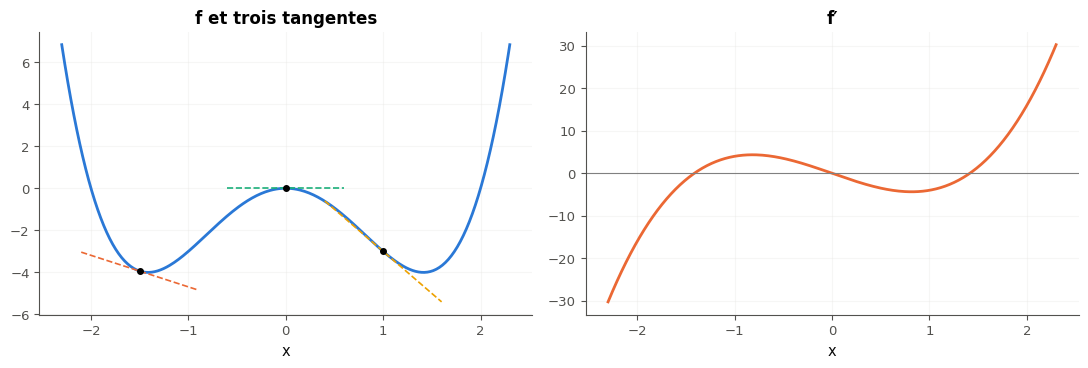

In [36]:
def plot_f_and_tangents(axes, f, df, points):
    """axes[0]: f on [-2.3, 2.3] and its tangent at each p of points (on [p − 0.6, p + 0.6]); axes[1]: df and y = 0."""
    xs = np.linspace(-2.3, 2.3, 300)
    axes[0].plot(xs, f(xs), linewidth=2, label="f")
    for p in points:
        segment = np.linspace(p - 0.6, p + 0.6, 2)
        axes[0].plot(segment, f(p) + df(p) * (segment - p), "--", linewidth=1.2)
        axes[0].plot([p], [f(p)], "o", color="black", markersize=4)
    axes[0].set_title("f et trois tangentes")
    axes[1].plot(xs, df(xs), linewidth=2, color="C1")
    axes[1].axhline(0, color="gray", linewidth=0.8)
    axes[1].set_title("f′")
    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.set_xlabel("x")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_f_and_tangents(axes, f23, df23, points23)
fig.tight_layout()
plt.show()
answer_R7_23a = [round(-math.sqrt(2), 3), 0.0, round(math.sqrt(2), 3)]
answer_R7_23b = 2

In [37]:
wbm.record("R7.23a", [-math.sqrt(2), 0.0, math.sqrt(2)], decimals=3,
           mistakes={"f′(x) = 4x(x² − 2) s'annule en trois points": [-math.sqrt(2), math.sqrt(2)],
                     "ce sont les zéros de f′, pas ceux de f": [-2, 0, 2]})
wbm.record("R7.23b", 2, mistakes={"en 0, f′ passe de + à − : c'est un maximum local": 3})

WBM_ANSWER {"decimals": 3, "element_coarse": [["6daa3003328acd9d56e3fccd8084bb833b341602fdc1a8f97ed1421e1bde842e"], ["a2750f1cc587250872dee794dd2070093ced981110b2bcb71ce322522b0b8e43"], ["6f5fa34e6ad622394f22eace63cea890ad7ed88a4b833ef9512fcdaaba0172ed"]], "element_hashes": ["db7da2f797cd5c21d30b81adf7cc245f40c6b02f902dde6e1a93e63c64766c76", "9bf67c11d30e38871f851b61259b81da5d0ad808c61320e315fadeea41a7da0d", "26d0b50c365fc97bb0acf4d1e1d89b70e3358ba808c0d8d8ec455cef5cdb2436"], "hash": "50892beb9774205b710a657c9a9d8c123a3585fdb039e9938877ad04a818d790", "id": "R7.23a", "kind": "array", "mistakes": {"02a6ebdfe47185c50196848b7ac9b05be5be8fb18862f6be4a41022fb7aeff20": "f′(x) = 4x(x² − 2) s'annule en trois points", "bfb2fa7f434648d64e7020a26040f6ed955300bbb4f2320df91dba266c7ba601": "ce sont les zéros de f′, pas ceux de f"}, "shape": [3]}
📝 Ex R7.23a : réponse enregistrée (array, 3 décimale(s)).
WBM_ANSWER {"hash": "9dd4cbae3d3753dadcff2bc6bc48da95199fbce0535499422fe1886e7d94792a", "id": "R7.2

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [38]:
with checked("R7.23 vérifications"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    try:
        created = drawn(plot_f_and_tangents, axes, f23, df23, points23)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    problems = []
    if created:
        problems.append("ta fonction ouvre sa propre figure : dessine dans les axes reçus (axes[0].plot, …)")
    else:
        lines0 = [(np.asarray(l.get_xdata(), dtype=float), np.asarray(l.get_ydata(), dtype=float))
                  for l in axes[0].lines]
        lines1 = [(np.asarray(l.get_xdata(), dtype=float), np.asarray(l.get_ydata(), dtype=float))
                  for l in axes[1].lines]
        if not any(len(xs) > 20 and np.allclose(ys, f23(xs)) for xs, ys in lines0):
            problems.append("la courbe de f n'est pas tracée dans axes[0] (au moins 20 points)")
        for p in points23:
            if not any(len(xs) >= 2 and np.allclose(ys, f23(p) + df23(p) * (xs - p)) and xs.min() < p < xs.max()
                       for xs, ys in lines0):
                problems.append(f"pas de tangente en {p} dans axes[0] : la droite y = f(p) + f′(p)(x − p), "
                                f"tracée de part et d'autre de p")
        if not any(len(xs) > 20 and np.allclose(ys, df23(xs)) for xs, ys in lines1):
            problems.append("la courbe de f′ n'est pas tracée dans axes[1] (au moins 20 points)")
        if not any(len(ys) >= 2 and np.allclose(ys, 0) for xs, ys in lines1):
            problems.append("la droite y = 0 dans axes[1] (axes[1].axhline(0))")
        if not all(ax.get_title() for ax in axes):
            problems.append("un titre pour chaque graphique (ax.set_title)")
    if problems:
        print("❌ Ex R7.23 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R7.23 : f, ses trois tangentes et f′, avec la droite y = 0.")

✅ Ex R7.23 : f, ses trois tangentes et f′, avec la droite y = 0.


💡 $f'(x) = 4x^3 - 8x = 4x(x^2 - 2)$ s'annule en $-\sqrt{2}$, 0 et $\sqrt{2}$ : deux minimums locaux ($f(\pm\sqrt{2}) = -4$) et un maximum local ($f(0) = 0$). La tangente en 1 a la pente $f'(1) = -4$ : c'est la hauteur de la courbe de droite en 1.

## Partie C · Dérivées fausses et tests

Fiche §5 à §7. Quatre dérivées fausses à trouver, puis un test qui vérifie une dérivée.

### Ex R7.24 — Chasse à l'erreur : quatre dérivées fausses 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer des dérivées fausses dans du code (règle du produit, règle de la chaîne), les corriger et les vérifier par un taux d'accroissement.  
**Prérequis :** fiche §6 et §7 · **Parcours :** C, E

Six fonctions Python calculent les dérivées de six fonctions (écrites en commentaire). Certaines lignes sont fausses. **Sans rien exécuter d'abord**, trouve-les.

```python
def d_a(x):  # derivative of x**4 * ln(x)
    return 4 * x ** 3 * (1 / x)                                   # (A)


def d_b(x):  # derivative of (x - 1) / (x + 1)
    return 2 / (x + 1) ** 2                                       # (B)


def d_c(x):  # derivative of exp(3 * x)
    return math.exp(3 * x)                                        # (C)


def d_d(x):  # derivative of ln(x**2 + 5)
    return 1 / (x ** 2 + 5)                                       # (D)


def d_e(x):  # derivative of sqrt(2 * x)
    return 1 / (2 * math.sqrt(2 * x))                             # (E)


def d_f(x):  # derivative of x**3 - 1 / x
    return 3 * x ** 2 + 1 / x ** 2                                # (F)
```

- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;

Puis corrige-les dans la cellule ci-dessous (elle contient le code fautif). La fonction `slope(f, x)` de la cellule fournie calcule un taux d'accroissement avec $h = 10^{-6}$ : compare-le à chacune de tes dérivées en $x = 2$ pour les vérifier. La vérification calcule b), la liste `[d_a(2), d_c(2), d_d(2), d_e(2)]`.

Dans ta copie : pour chaque ligne fausse, quelle règle a été oubliée ? Laquelle des deux lignes justes pouvait sembler fausse, et pourquoi ne l'est-elle pas ?

In [39]:
def slope(f, x, h=1e-6):
    """A rate of change of f between x and x + h: close to f'(x) for a small h (fiche §3)."""
    return (f(x + h) - f(x)) / h

In [40]:
answer_R7_24a = "ACDE"

def d_a(x):  # derivative of x**4 * ln(x)
    return 4 * x ** 3 * math.log(x) + x ** 3                      # (A) corrected: the product rule


def d_b(x):  # derivative of (x - 1) / (x + 1)
    return 2 / (x + 1) ** 2                                       # (B)


def d_c(x):  # derivative of exp(3 * x)
    return 3 * math.exp(3 * x)                                    # (C) corrected: times the derivative of 3x


def d_d(x):  # derivative of ln(x**2 + 5)
    return 2 * x / (x ** 2 + 5)                                   # (D) corrected: u'/u


def d_e(x):  # derivative of sqrt(2 * x)
    return 2 / (2 * math.sqrt(2 * x))                             # (E) corrected: times the derivative of 2x


def d_f(x):  # derivative of x**3 - 1 / x
    return 3 * x ** 2 + 1 / x ** 2                                # (F)


print(answer_R7_24a, [d_a(2), d_c(2), d_d(2), d_e(2)])
print("vérification par des taux :", [slope(lambda x: x ** 4 * math.log(x), 2), slope(lambda x: math.exp(3 * x), 2),
                                      slope(lambda x: math.log(x ** 2 + 5), 2), slope(lambda x: math.sqrt(2 * x), 2)])

ACDE [30.18070977791825, 1210.2863804782053, 0.4444444444444444, 0.5]
vérification par des taux : [30.180740417051766, 1210.2881960913692, 0.4444444567930361, 0.4999999374533104]


In [41]:
wbm.record("R7.24a", "ACDE",
           mistakes={"il manque une ligne fautive : x⁴ ln x est un produit : sa dérivée n'est pas le produit des dérivées": "CDE",
                     "il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ADE",
                     "il manque une ligne fautive : ln(x² + 5) est une composée : (ln u)′ = u′/u": "ACE",
                     "il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ACD",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABCDE",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "ACDEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : x⁴ ln x est un produit : sa dérivée n'est pas le produit des dérivées": "BCDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : x⁴ ln x est un produit : sa dérivée n'est pas le produit des dérivées": "CDEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ABDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ADEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : ln(x² + 5) est une composée : (ln u)′ = u′/u": "ABCE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : ln(x² + 5) est une composée : (ln u)′ = u′/u": "ACEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ABCD",
                     "la ligne (F) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ACDF",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D", "E", "AC", "AD", "AE", "CD", "CE", "DE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "F", "AB", "AF", "BC", "BD", "BE", "BF", "CF", "DF", "EF", "ABC", "ABD", "ABE", "ABF", "ACF", "ADF", "AEF", "BCD", "BCE", "BCF", "BDE", "BDF", "BEF", "CDF", "CEF", "DEF", "ABCF", "ABDF", "ABEF", "BCDF", "BCEF", "BDEF", "ABCDF", "ABCEF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("R7.24b", [32 * math.log(2) + 8, 3 * math.exp(6), 4 / 9, 0.5], decimals=4,
           mistakes={"aucune des quatre lignes fausses n'est encore corrigée : corrige-les dans la cellule où tu as "
                     "écrit a)": [4 * 8 / 2, math.exp(6), 1 / 9, 1 / (2 * math.sqrt(4))],
                     "d_a : la règle du produit donne deux termes": [32 * math.log(2), 3 * math.exp(6), 4 / 9, 0.5]})

WBM_ANSWER {"hash": "30eafdbd7b7841c598dbde6bf4e311e411ea08ff004b5ae04727c15c59e4d350", "id": "R7.24a", "kind": "str", "mistakes": {"0028c19a010dc171273b28387d449e75b3a8e837e883cff0e14053c5f3e1c7c3": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0f8c2aab38e3d57556159fe88050b12836297d0acee006e9d951f38ec406e2f4": "la ligne (B) est correcte, et il manque une ligne fautive : x⁴ ln x est un produit : sa dérivée n'est pas le produit des dérivées", "127c5ae4fa4f09d1228407510bed49c94a1409e5efaacba5cb87ef98851f6f19": "la ligne (B) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2", "184533b87144e30d3ac77c2719ce9907c31a974004bdc296842e2754b436d35d": "la ligne (B) est correcte, et il manque une ligne fautive : ln(x² + 5) est une composée : (ln u)′ = u′/u", "20d28a603e65fa792f8549c2d16e5b8dfac97ac9051bcbffc7148378a232f345": "il manque des lignes fautives, et des 

💡 (A) $(x^4 \ln x)' = 4x^3 \ln x + x^3$, la règle du produit. (C) $(e^{3x})' = 3e^{3x}$. (D) $(\ln(x^2 + 5))' = \frac{2x}{x^2 + 5}$. (E) $(\sqrt{2x})' = \frac{2}{2\sqrt{2x}} = \frac{1}{\sqrt{2x}}$. (B) est juste : $\frac{1 \times (x + 1) - (x - 1) \times 1}{(x + 1)^2} = \frac{2}{(x + 1)^2}$. (F) aussi : la dérivée de $-\frac{1}{x}$ est $+\frac{1}{x^2}$.

### Ex R7.25 — Tester une dérivée avec pytest et SymPy 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test qui compare une dérivée calculée à la main à celle de SymPy, et vérifier qu'il sait dire non.  
**Prérequis :** fiche §5 et §6 ; R0 (pytest) · **Parcours :** C

Une dérivée calculée à la main se vérifie par un **test** : une fonction `test_...` que pytest exécute, et qui échoue si la dérivée est fausse. Ici :
1. Écris `dg(x)`, la dérivée de $g(x) = \frac{x^2 + 1}{x + 3}$, **calculée à la main** (règle du quotient, simplifiée) ;
2. Écris `test_dg_matches_sympy()` : il calcule la dérivée de $g$ avec SymPy (`sp.diff`), puis vérifie avec `assert` et `math.isclose` que `dg` donne la même valeur qu'elle en au moins quatre points (pense à un point négatif ; évite −3). Pour évaluer une expression SymPy en un point : `float(expression.subs(X, point))`.

La vérification lance ton test avec pytest (`wbm.run_pytest`) deux fois : sur ta `dg`, où il doit passer ; puis sur `dg_bug` (fournie), une dérivée fausse, où il doit **échouer**. Un test qui ne sait pas dire non ne vérifie rien.
- a) ton test passe-t-il sur `dg` ? ; b) échoue-t-il sur `dg_bug` ?

In [42]:
def dg_bug(x):
    """A wrong derivative of g(x) = (x**2 + 1) / (x + 3): u'v + uv' over v², with a + instead of a −."""
    return (2 * x * (x + 3) + (x ** 2 + 1)) / (x + 3) ** 2

In [43]:
def dg(x):
    """The derivative of g(x) = (x**2 + 1) / (x + 3), computed by hand (x != -3)."""
    return (x ** 2 + 6 * x - 1) / (x + 3) ** 2


def test_dg_matches_sympy():
    """dg agrees with the derivative of g computed by SymPy, at four points or more."""
    X = sp.symbols("x")
    exact = sp.diff((X ** 2 + 1) / (X + 3), X)
    for point in (-2.5, -1, 0, 0.5, 2, 10):
        assert math.isclose(dg(point), float(exact.subs(X, point)), rel_tol=1e-12, abs_tol=1e-12)


good = wbm.run_pytest(test_dg_matches_sympy, subject=dg, preamble="import sympy as sp", quiet=True)
bad = wbm.run_pytest(test_dg_matches_sympy, subject=dg_bug, name="dg", preamble="import sympy as sp", quiet=True)
print(f"sur dg : {good.summary} ; sur dg_bug : {bad.summary}")

sur dg : 1 passed in 0.27s ; sur dg_bug : 1 failed in 0.27s


In [44]:
wbm.record("R7.25a", True,
           mistakes={"ton test échoue sur ta propre dg : relis ta dérivée (u′v − uv′ sur v²) ou ton test (lis la sortie "
                     "de pytest : print(good.output))": False})
wbm.record("R7.25b", True,
           mistakes={"ton test ne voit pas l'erreur de dg_bug : compare en plusieurs points, avec une tolérance serrée "
                     "(math.isclose)": False})

WBM_ANSWER {"hash": "235b2bfb99ca0473995157abfa00a042353a27865709524185317f080a9a7ac8", "id": "R7.25a", "kind": "bool", "mistakes": {"487336a30d78c6c2145e8856dd3b0c84e7a7f1e061a94bfd4bfbc926f7a445ea": "ton test échoue sur ta propre dg : relis ta dérivée (u′v − uv′ sur v²) ou ton test (lis la sortie de pytest : print(good.output))"}}
📝 Ex R7.25a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "d2046ec84bb09a5e96dbc86a8446fb6d349205ca13a087c194dd0cc630467a31", "id": "R7.25b", "kind": "bool", "mistakes": {"7bc901e777d53840e8e0febd67328048ccce828acf56d22493a1264bcc14211e": "ton test ne voit pas l'erreur de dg_bug : compare en plusieurs points, avec une tolérance serrée (math.isclose)"}}
📝 Ex R7.25b : réponse enregistrée (bool).


💡 $g'(x) = \frac{2x(x + 3) - (x^2 + 1)}{(x + 3)^2} = \frac{x^2 + 6x - 1}{(x + 3)^2}$. Un test qui compare en un seul point peut tomber sur un point où une dérivée fausse est juste par hasard ; plusieurs points, dont un négatif, rendent ce hasard très improbable.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu une limite en l'infini ou en un point, et repères-tu une asymptote ?
2. Dérives-tu sans hésiter un produit, un quotient et une composée, et écris-tu une tangente ?
3. Sais-tu étudier les variations d'une fonction et trouver son minimum, y compris aux bords ?

**La suite** : R8, *Probabilités de base*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.